# Car Price Prediction: Linear Regression vs Random Forest


## 1. Imports and load

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

DATA_PATH = "Car Dataset.csv"   # change if your file has another name or path
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])

(8368, 16)
Engine Fuel Type        1
Engine HP              63
Engine Cylinders       10
Transmission Type       1
Driven_Wheels           1
Number of Doors         7
Market Category      2519
Vehicle Size            1
Vehicle Style           1
highway MPG             1
city mpg                1
Popularity              1
MSRP                    1
dtype: int64


## 2. Cleaning

In [34]:
#2. Cleaning (before splitting)

df = df.drop_duplicates().reset_index(drop=True)
df = df.drop(columns=["Market Category"], errors="ignore")
for c in ["MSRP", "Year", "Engine HP", "Engine Cylinders", "Number of Doors",
          "highway MPG", "city mpg", "Popularity"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)

# drop rows where the price is missing, zero or negative
df = df[df["MSRP"] > 0].reset_index(drop=True)
print(df.shape)

(7854, 15)


# 3. Choosing features and target

In [35]:
TARGET = "MSRP"
NUM = ["Year", "Engine HP", "Engine Cylinders", "Number of Doors",
       "highway MPG", "city mpg", "Popularity"]
CAT = ["Make", "Engine Fuel Type", "Transmission Type",
       "Driven_Wheels", "Vehicle Size", "Vehicle Style"]

X = df[NUM + CAT]
y = np.log1p(df[TARGET])        # MSRP is heavily right-skewed, so model log(price)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

#4. Preprocessing 

In [36]:
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
prep = ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

models = {
    "Linear Regression": Pipeline([("prep", prep), ("model", LinearRegression())]),
    "Random Forest": Pipeline([("prep", prep),
                               ("model", RandomForestRegressor(
                                   n_estimators=200, random_state=42, n_jobs=-1))]),
}

#5. Training and evaluation

In [37]:
def evaluate(name, pipe):
    pipe.fit(X_train, y_train)
    pred = np.expm1(pipe.predict(X_test))
    actual = np.expm1(y_test)
    return {
        "Model": name,
        "R2 (log price)": r2_score(y_test, pipe.predict(X_test)),
        "R2 ($)": r2_score(actual, pred),
        "MAE ($)": mean_absolute_error(actual, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
    }

results = pd.DataFrame([evaluate(n, p) for n, p in models.items()]).round(3)
print(results.to_string(index=False))

            Model  R2 (log price)  R2 ($)   MAE ($)  RMSE ($)
Linear Regression           0.866   0.814 10370.166 21470.352
    Random Forest           0.992   0.985  3185.757  6203.996


#6. Cross-validation

In [ ]:
for name, pipe in models.items():
    scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
    print(f"{name}: mean R2 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Linear Regression: mean R2 = 0.788 (+/- 0.039)


## 7. Predicted vs actual (Random Forest)

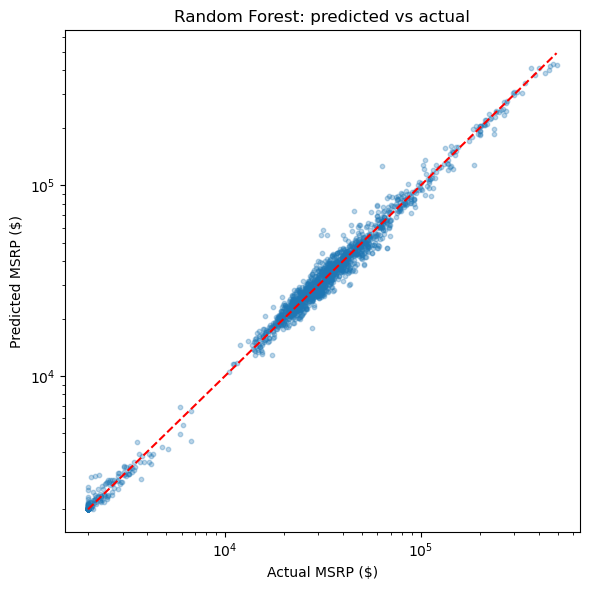

In [ ]:
rf = models["Random Forest"]
pred = np.expm1(rf.predict(X_test))
actual = np.expm1(y_test)
plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.3, s=10)
lim = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
plt.plot(lim, lim, "r--")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual MSRP ($)"); plt.ylabel("Predicted MSRP ($)")
plt.title("Random Forest: predicted vs actual")
plt.tight_layout(); plt.savefig("pred_vs_actual.png", dpi=150); plt.show()

## 8. Feature importance (Random Forest)

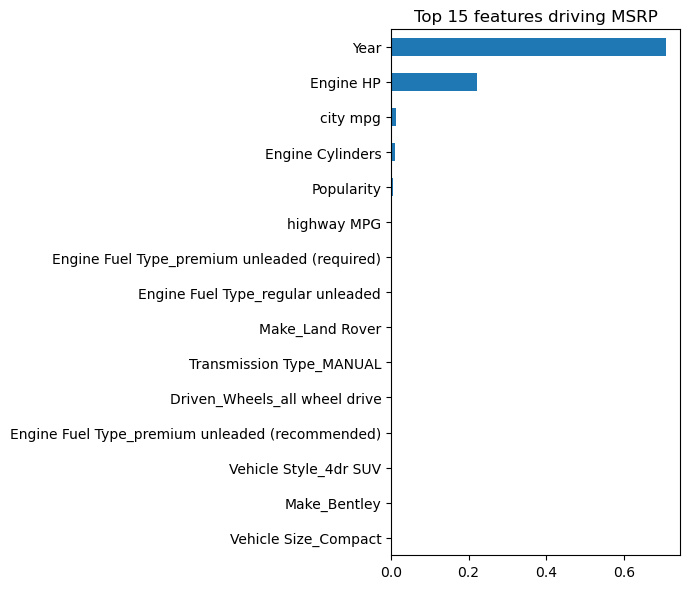

In [ ]:
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)
top = imp.sort_values(ascending=False).head(15)[::-1]
top.index = [i.split("__", 1)[-1] for i in top.index]
top.plot(kind="barh", figsize=(7, 6), title="Top 15 features driving MSRP")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

## 9. Saving the best model and predict one car

In [ ]:
joblib.dump(rf, "car_price_rf.joblib")
example = pd.DataFrame([{
    "Year": 2016, "Engine HP": 300, "Engine Cylinders": 6, "Number of Doors": 4,
    "highway MPG": 28, "city mpg": 20, "Popularity": 1500, "Make": "BMW",
    "Engine Fuel Type": "premium unleaded (required)",
    "Transmission Type": "AUTOMATIC", "Driven_Wheels": "rear wheel drive",
    "Vehicle Size": "Midsize", "Vehicle Style": "Sedan"}])
print("Predicted MSRP: $", round(float(np.expm1(rf.predict(example))[0])))

Predicted MSRP: $ 45078
